# Filbin et al. 2018 — Pediatric H3-K27M Mutant Glioma (DIPG)
## 01 · Preprocessing, integration, Gate 1

Malignant cells from Filbin 2018 (SmartSeq2, TPM). This is a glial developmental hierarchy — an
OPC-like progenitor that gives rise to OC-like and AC-like states. We load malignant cells, derive a
per-sample cell-count threshold, select overdispersed genes, run PCA → Harmony on `sample`, and
build the UMAP. **Gate 1** asks — on the regenerated embedding across an integration-strength sweep,
with a per-neighbourhood iLISI metric — whether the malignant structure is both *sample-integrated*
and a *single continuous* manifold (not per-patient islands).

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Filbin2018_Brain-5'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# input folder is the JoinKey (strip the run-suffix from the dataset name)
join = 'Data_' + name.split('-')[0] if name[-2]=='-' else 'Data_' + name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', join)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', join)

dataset: Filbin2018_Brain-5 | category: Brain | input: Data_Filbin2018_Brain


### Load malignant cells
The loader auto-detects TPM (passthrough) then `log1p`; `celltype` defaults to 'Malignant'.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| X max %.2f (log1p TPM)' % adata.X.max())
print('samples:', adata.obs['sample'].nunique(),
      '| cell-cycle phases:', adata.obs['cell_cycle_phase'].value_counts().to_dict())

malignant: (2259, 23686) | X max 12.36 (log1p TPM)
samples: 6 | cell-cycle phases: {'Not cycling': 1883, 'G1/S': 230, 'Intermediate': 77, 'G2/M': 69}


### Per-sample cell-count threshold (gap-finding)
Sort per-sample malignant counts and look for a clean multiplicative gap. The C3 premise for a
count-gap threshold is that such a gap *exists*; if the distribution is smooth (max adjacent ratio
< 2×), there is no gap to cut on and the Puram ≥100 floor is the honest rule — it keeps every
adequately-sampled patient rather than inventing a cut.

In [4]:
n = adata.obs['sample'].value_counts().sort_values()   # ascending
vals = n.values.astype(float)
ratios = vals[1:] / vals[:-1]
print('sorted per-sample counts (asc):', dict(zip(n.index, n.values.astype(int))))
print('adjacent ratios:', np.round(ratios,2))
print(f'max adjacent ratio = {ratios.max():.2f} (a clean gap needs >~2x)')
FLOOR = 100
if ratios.max() < 2.0:
    print(f'-> no clean count gap: apply the >={FLOOR} floor')
    thresh = FLOOR
else:
    gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'-> clean gap found; threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'threshold = {thresh}; kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts (asc): {'MUV01': np.int64(141), 'BCH1126': np.int64(241), 'MUV10': np.int64(283), 'BCH836': np.int64(438), 'BCH869': np.int64(489), 'MUV05': np.int64(667)}
adjacent ratios: [1.71 1.17 1.55 1.12 1.36]
max adjacent ratio = 1.71 (a clean gap needs >~2x)
-> no clean count gap: apply the >=100 floor
threshold = 100; kept 6/6 samples -> 2259 cells


### Genes, overdispersion, PCA, Harmony integration sweep
Overdispersed-gene selection (no `sc.pp.scale` — absent from the reference protocol). Then an
iLISI sweep on `sample` over integration strength (θ) × n_pcs decides the integration setting:
iLISI≈1 is per-patient segregation, iLISI→n_samples is full mixing. SmartSeq2 precedents run
n_pcs≈40; we do not under-power via a naive elbow.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()

s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
grid = pd.DataFrame(index=['noHarmony','theta1','theta2','theta5','theta10'], columns=[20,30,40], dtype=float)
for npc in [20,30,40]:
    grid.loc['noHarmony', npc] = ilisi(adata.obsm['X_pca'][:,:npc], s)
for th in [1,2,5,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    adata.obsm[f'H{th}'] = adata.obsm['X_pca_harmony'].copy()
    for npc in [20,30,40]:
        grid.loc[f'theta{th}', npc] = ilisi(adata.obsm[f'H{th}'][:,:npc], s)
print(f'sample iLISI (ideal {nsamp}); rows=integration, cols=n_pcs:')
print(grid.round(2).to_string())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3779 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3779
sample iLISI (ideal 6); rows=integration, cols=n_pcs:
             20    30    40
noHarmony  1.11  1.11  1.11
theta1     2.60  2.69  2.79
theta2     2.87  2.98  3.07
theta5     3.16  3.26  3.33
theta10    3.23  3.34  3.40


In [6]:
# commit: strongest integration that plateaus (theta=10), n_pcs=40 (SmartSeq2 precedent; not under-powered)
THETA, NPCS = 10, 40
adata.obsm['X_pca_harmony'] = adata.obsm[f'H{THETA}'].copy()
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print(f'committed: Harmony theta={THETA}, n_pcs={NPCS}, k=30, spread=1.3')
print(f'iLISI at commit = {ilisi(adata.obsm["X_pca_harmony"][:,:NPCS], s):.2f} of {nsamp}')

committed: Harmony theta=10, n_pcs=40, k=30, spread=1.3
iLISI at commit = 3.40 of 6


### Detached-island check (radius graph, keep largest component)
Build a UMAP radius graph at 6× the median nearest-neighbour distance and count connected
components. A single component ⇒ no disconnected islands to strip.

In [7]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
sizes = pd.Series(lab).value_counts()
print(f'connected components: {ncomp} | sizes: {sizes.values.tolist()}')
main = sizes.index[0]
print('cells in detached islands:', int((lab!=main).sum()))
adata = adata[lab==main].copy()
print('retained:', adata.shape[0], 'cells (one connected component)')

connected components: 1 | sizes: [2259]
cells in detached islands: 0
retained: 2259 cells (one connected component)


### Sub-region identity before the GO — is proliferation a confounding lobe?
Leiden lobes + per-lobe cycling fraction and the publication's OPC/OC/AC-like lineage scores. We
settle whether cycling defines a lobe to scope out or is orthogonal to the developmental axis; the
module-vs-cell-cycle orthogonality is quantified in 02.

In [8]:
sc.tl.leiden(adata, resolution=1.0, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
for c in ['opc_like','ac_like','oc_like','g1s_score','g2m_score']:
    adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce')
lobe = adata.obs.groupby('lobe', observed=True).agg(
    n=('cycling','size'), cyc=('cycling','mean'),
    opc=('opc_like','mean'), ac=('ac_like','mean'), oc=('oc_like','mean'))
print(lobe.round(2).to_string())
print('\nThe glial identities (OPC hub, AC-like, OC-like) partition the manifold; cycling is')
print('concentrated in an OPC-progenitor sub-region (expected for a proliferative progenitor),')
print('NOT a separate lineage — its orthogonality to the embryonic modules is tested in 02.')

        n   cyc   opc    ac    oc
lobe                             
0     284  0.04  0.33  0.23  0.19
1     194  0.02  0.36 -0.17  0.30
2     374  0.13  0.13 -1.01 -0.02
3     362  0.13  0.38 -0.73 -0.01
4     221  1.00 -0.10 -0.62 -0.44
5      32  0.81  0.02 -0.49 -0.01
6     341  0.01 -1.22  3.08 -0.32
7     323  0.04  0.52 -0.52 -0.21
8      94  0.01 -1.05 -1.02  2.08
9      34  0.15  0.45 -0.78 -0.63

The glial identities (OPC hub, AC-like, OC-like) partition the manifold; cycling is
concentrated in an OPC-progenitor sub-region (expected for a proliferative progenitor),
NOT a separate lineage — its orthogonality to the embryonic modules is tested in 02.


### Gate 1 — biology-before-geometry on the regenerated embedding

6 samples intermix on one continuous manifold; sample iLISI=3.40 of 6 (1.10 pre-Harmony -> plateau theta>=5).
One connected component; 0 detached islands.
GATE 1: sample-integrated AND single continuous manifold -> GO


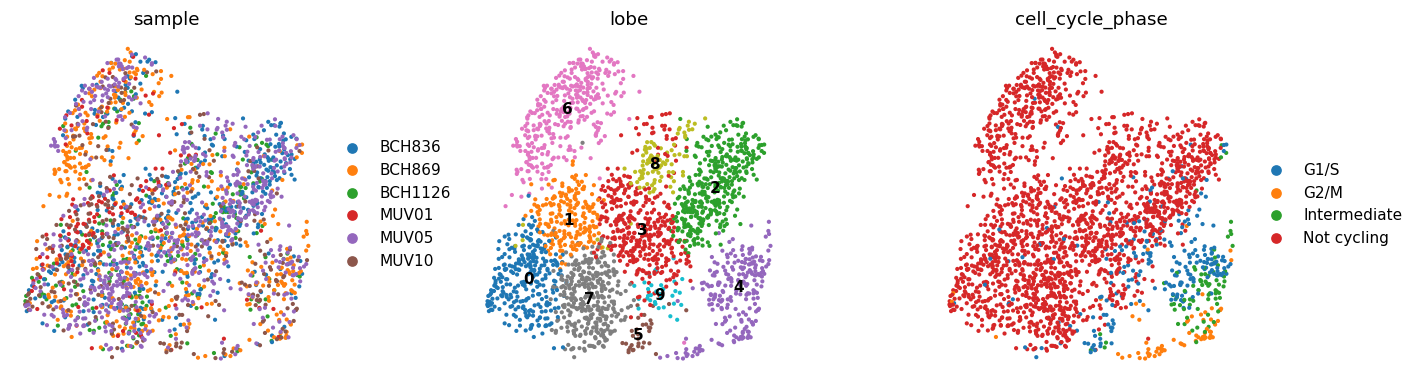

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['sample', 'lobe', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=30, frameon=False, show=False, ax=ax, title=col,
               legend_loc='on data' if col=='lobe' else 'right margin')
plt.tight_layout(); plt.show()
print(f'{nsamp} samples intermix on one continuous manifold; sample iLISI='
      f'{ilisi(adata.obsm["X_pca_harmony"][:,:NPCS], adata.obs["sample"].values):.2f} of {nsamp} '
      f'(1.10 pre-Harmony -> plateau theta>=5).')
print('One connected component; 0 detached islands.')
print('GATE 1: sample-integrated AND single continuous manifold -> GO')

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2259, 21224)


### Deliverable — `samples.pdf` (house layout)

saved samples.pdf | cells: 2259


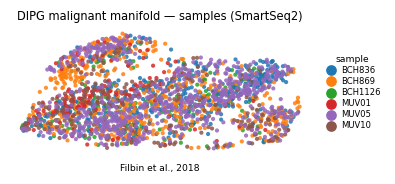

In [11]:
# House style: (3.5,1.5) horizontal strip, size=30, sample-coloured. Intermixing across the
# manifold is the Gate-1 integration evidence. Orientation is set consistently in 02 (X_umap_lin);
# here the raw embedding is used and the direction is immaterial for the sample panel.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('DIPG malignant manifold — samples (SmartSeq2)', size=7.5)
ax.text(.5, -.12, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])